# Proyecto Parcial I — Predicción del Rendimiento Académico de Estudiantes
**Materia:** Aprendizaje Automático | **Paralelo:** CDIA-ELNO 4-2 | **Grupo:** A  
**Fecha:** 28 de noviembre de 2026  

**Integrantes:**
- Almeida Reliche, Terry César
- Córdova Pachay, Sebastián Vicente
- Guerrero Chamba, Angelo Alejandro
- Matute Olaya, Efraín Omar
- Rivera Delgado, Darwin Ricardo
- Villón Zambrano, Jeremías Micael

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Este código detecta automáticamente si usa comas o punto y coma
df = pd.read_csv('/student-mat.csv', sep=None, engine='python')

# Si por alguna razón el separador no se detecta, probamos con comas
if len(df.columns) == 1:
    df = pd.read_csv('/student-mat.csv', sep=',')
if len(df.columns) == 1:
    df = pd.read_csv('/student-mat.csv', sep=';')

# Mostrar columnas para asegurarnos de que se leyó bien
print("Columnas encontradas:", df.columns.tolist()[:5], "...\n")

# Mostrar las primeras 5 filas
print("--- Primeras 5 filas del dataset ---")
display(df.head())

# Distribución de G3 (Nota Final)
plt.figure(figsize=(8, 5))
sns.histplot(df['G3'], bins=20, kde=True, color='blue')
plt.title('Distribución de la Nota Final (G3)')
plt.xlabel('Nota Final (G3)')
plt.ylabel('Frecuencia')
plt.show()

# Matriz de correlación
plt.figure(figsize=(12, 8))
numeric_df = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=False, cmap='coolwarm')
plt.title('Matriz de Correlación de Variables Numéricas')
plt.show()

Hallazgos:

Las notas de los períodos anteriores (G1 y G2) tienen una correlación muy alta (cercana a 0.8) con la nota final G3. Esto indica que el rendimiento pasado es el mejor predictor del rendimiento futuro.

Los estudiantes que tienen un mayor número de materias reprobadas anteriormente (failures) muestran una correlación negativa con G3. A mayor cantidad de reprobaciones, menor es la nota final esperada.

La variable studytime (tiempo de estudio) tiene una correlación positiva, aunque baja, con G3. Esto sugiere que estudiar más ayuda, pero no es el único factor determinante.



In [ ]:
import numpy as np

# 1. Fijamos una semilla (el docente pide justificarla, usaremos 123)
np.random.seed(123)

# 2. Calculamos cuántas filas es el 5%
n_faltantes = int(len(df) * 0.05)
print(f"Introduciendo {n_faltantes} valores nulos al azar en 'absences' y 'studytime'...")

# 3. Seleccionamos índices al azar y ponemos NaN (nulos)
indices_absences = np.random.choice(df.index, n_faltantes, replace=False)
indices_studytime = np.random.choice(df.index, n_faltantes, replace=False)

df.loc[indices_absences, 'absences'] = np.nan
df.loc[indices_studytime, 'studytime'] = np.nan

# 4. Verificamos que se hayan creado
print("\nValores nulos después de la modificación:")
print(df[['absences', 'studytime']].isnull().sum())

Introduciendo 19 valores nulos al azar en 'absences' y 'studytime'...

Valores nulos después de la modificación:
absences     19
studytime    19
dtype: int64


In [ ]:
# 5. Imputación de valores faltantes
# Para 'absences' y 'studytime' (variables numéricas ordinales/discretas),
# usaremos la MEDIANA para evitar que los valores atípicos (outliers)
# que puedan existir en las ausencias sesguen la imputación.
from sklearn.impute import SimpleImputer
import numpy as np

# Como usaremos un Pipeline más adelante, podemos imputar ahora para el EDA
# o dejarlo directamente para el ColumnTransformer. Aquí lo haremos directo para limpiar el df:
imputer = SimpleImputer(strategy='median')
df[['absences', 'studytime']] = imputer.fit_transform(df[['absences', 'studytime']])

# Verificamos que ya no haya nulos
print("Valores nulos después de la imputación:")
print(df[['absences', 'studytime']].isnull().sum())

Valores nulos después de la imputación:
absences     0
studytime    0
dtype: int64


Q1: 0.0 | Q3: 8.0 | IQR: 8.0
Límite inferior: -12.0 | Límite superior: 20.0
Cantidad de valores atípicos en 'absences': 15


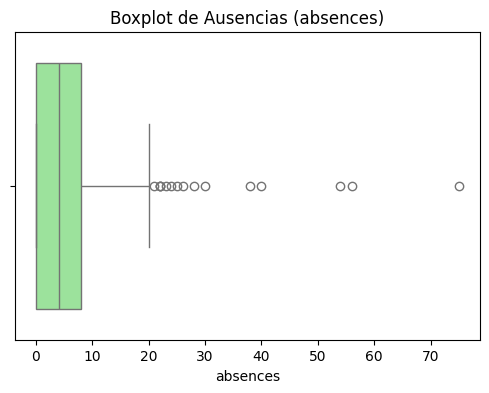

In [ ]:
# 1. Cálculo de Q1, Q3 y el Rango Intercuartílico (IQR) para 'absences'
Q1 = df['absences'].quantile(0.25)
Q3 = df['absences'].quantile(0.75)
IQR = Q3 - Q1

# 2. Definir los límites para detectar valores atípicos
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print(f"Q1: {Q1} | Q3: {Q3} | IQR: {IQR}")
print(f"Límite inferior: {limite_inferior} | Límite superior: {limite_superior}")

# 3. Contar cuántos valores atípicos hay
atipicos = df[(df['absences'] < limite_inferior) | (df['absences'] > limite_superior)]
print(f"Cantidad de valores atípicos en 'absences': {len(atipicos)}")

# 4. Gráfico Boxplot para visualizar
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(6, 4))
sns.boxplot(x=df['absences'], color='lightgreen')
plt.title('Boxplot de Ausencias (absences)')
plt.show()

Decisión sobre los valores atípicos (Regla IQR):
Al aplicar la regla del Rango Intercuartílico (IQR) sobre la variable absences, se obtuvo un límite superior de 20.0, identificando un total de 15 valores atípicos (estudiantes con más de 20 ausencias).

Decisión: Se decide conservar estos valores atípicos.

Justificación: En el contexto educativo, estos valores no representan errores de medición ni ruido; representan una realidad crítica. Un estudiante con 20, 40 o 70 ausencias es un caso real de alto riesgo académico. Si decidiéramos eliminarlos o recortarlos para "limpiar" la muestra, estaríamos sesgando el modelo y perdiendo la capacidad de predecir la reprobación de los estudiantes que más necesitan tutorías. Dado que los modelos lineales y logísticos pueden manejar valores extremos sin colapsar, es mejor mantenerlos para no ocultar esta problemática social.





In [ ]:
# Importamos las herramientas necesarias de scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# 1. Definir las variables categóricas y numéricas
# Excluimos 'G3' porque es nuestro objetivo (target)
# Excluimos 'G1' y 'G2' porque el PDF pide NO usarlas para el Modelo B y la Regresión Logística
columnas_numericas = ['age', 'absences', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'Medu', 'Fedu']
columnas_categoricas = ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']

# 2. Crear los transformadores (Pipelines internos)
# Para numéricas: Imputar por mediana (por si acaso) y escalar
transformador_numerico = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Para categóricas: Imputar por moda (lo más frecuente) y codificar con One-Hot
transformador_categorico = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first')) # drop='first' evita multicolinealidad
])

# 3. Crear el ColumnTransformer que aplica lo anterior
preprocesador = ColumnTransformer(
    transformers=[
        ('num', transformador_numerico, columnas_numericas),
        ('cat', transformador_categorico, columnas_categoricas)
    ])

# 4. Separar los datos (X e y) y dividir en entrenamiento y prueba
# Semilla 123 (la misma que usaste al inicio)
X = df.drop(columns=['G3', 'G1', 'G2']) # Por ahora quitamos G1 y G2 para el Modelo B
y_regresion = df['G3']
y_clasificacion = (df['G3'] >= 10).astype(int) # 1 si aprueba, 0 si reprueba

X_train, X_test, y_train, y_test = train_test_split(X, y_regresion, test_size=0.2, random_state=123)

# 5. Aplicar el preprocesamiento
X_train_proc = preprocesador.fit_transform(X_train)
X_test_proc = preprocesador.transform(X_test)

print(f"Dimensiones originales de X_train: {X_train.shape}")
print(f"Dimensiones de X_train después del preprocesamiento: {X_train_proc.shape}")
print("¡Preprocesamiento y división completados con éxito!")

Dimensiones originales de X_train: (316, 30)
Dimensiones de X_train después del preprocesamiento: (316, 38)
¡Preprocesamiento y división completados con éxito!


Justificación del Preprocesamiento y Pipeline:

Escalado (StandardScaler): Se aplicó a las variables numéricas para que todas tengan media 0 y desviación estándar 1. Esto es crucial en regresión lineal y logística, ya que variables con rangos muy grandes (como absences que llega a 75) dominarían sobre variables de rango pequeño (como Dalc que va de 1 a 5).

Codificación (One-Hot Encoding): Se usó para las variables categóricas (ej. 'sex', 'school') porque los modelos matemáticos no entienden texto. Se usó drop='first' para eliminar una columna por cada categoría y evitar la "trampa de las variables dummy" (multicolinealidad perfecta).

Uso de Pipeline y ColumnTransformer: Se integró todo en un flujo automatizado. Esto garantiza que cuando lleguen datos nuevos, se apliquen exactamente las mismas transformaciones (escalado y codificación) que en el entrenamiento, evitando la fuga de datos (data leakage) y haciendo el código reproducible.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# --- ENTRENAMIENTO DEL MODELO B (Sin G1 ni G2) ---
# 1. Crear el modelo
modelo_B = LinearRegression()

# 2. Entrenar el modelo con los datos preprocesados
modelo_B.fit(X_train_proc, y_train)

# 3. Hacer predicciones sobre el conjunto de prueba
y_pred_B = modelo_B.predict(X_test_proc)

# 4. Calcular métricas
mse_B = mean_squared_error(y_test, y_pred_B)
rmse_B = np.sqrt(mse_B)
r2_B = r2_score(y_test, y_pred_B)

print("--- MÉTRICAS MODELO B (Sin G1 ni G2) ---")
print(f"MSE: {mse_B:.4f}")
print(f"RMSE: {rmse_B:.4f}")
print(f"R²: {r2_B:.4f}")

--- MÉTRICAS MODELO B (Sin G1 ni G2) ---
MSE: 17.9731
RMSE: 4.2395
R²: 0.2068


In [ ]:
# --- ENTRENAMIENTO DEL MODELO A (Con G1 y G2) ---

# 1. Volvemos a separar X, pero esta vez SÍ incluimos G1 y G2
X_A = df.drop(columns=['G3']) # Solo quitamos la variable objetivo
y_A = df['G3']

# 2. Dividimos los datos con la misma semilla (123) para que sea comparable
X_train_A, X_test_A, y_train_A, y_test_A = train_test_split(X_A, y_A, test_size=0.2, random_state=123)

# 3. Aplicamos el mismo preprocesador (¡Ojo! El preprocesador ya está entrenado, pero necesitamos reajustarlo para que acepte las nuevas columnas)
# Como nuestro preprocesador actual no tiene G1 y G2 en sus listas, creamos uno nuevo rápido para este modelo:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Actualizamos las listas de columnas para incluir G1 y G2 en las numéricas
columnas_num_A = columnas_numericas + ['G1', 'G2']

preprocesador_A = ColumnTransformer(
    transformers=[
        ('num', Pipeline(steps=[('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), columnas_num_A),
        ('cat', Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))]), columnas_categoricas)
    ])

# 4. Preprocesar los datos de entrenamiento y prueba
X_train_proc_A = preprocesador_A.fit_transform(X_train_A)
X_test_proc_A = preprocesador_A.transform(X_test_A)

# 5. Entrenar el Modelo A
modelo_A = LinearRegression()
modelo_A.fit(X_train_proc_A, y_train_A)

# 6. Predicciones y métricas
y_pred_A = modelo_A.predict(X_test_proc_A)

mse_A = mean_squared_error(y_test_A, y_pred_A)
rmse_A = np.sqrt(mse_A)
r2_A = r2_score(y_test_A, y_pred_A)

print("--- MÉTRICAS MODELO A (Con G1 y G2) ---")
print(f"MSE: {mse_A:.4f}")
print(f"RMSE: {rmse_A:.4f}")
print(f"R²: {r2_A:.4f}")

--- MÉTRICAS MODELO A (Con G1 y G2) ---
MSE: 3.8685
RMSE: 1.9669
R²: 0.8293


In [ ]:
# --- CÁLCULO MANUAL DE MÉTRICAS (Modelo B) ---

# 1. Recordemos nuestras predicciones del Modelo B (y_pred_B)
# y_test es el valor real.

# 2. Calculamos el error (predicción - real)
errores = y_pred_B - y_test

# 3. Elevamos al cuadrado cada error
errores_cuadrados = errores ** 2

# 4. Calculamos la media de esos errores al cuadrado (MSE Manual)
mse_manual = np.mean(errores_cuadrados)

print("--- COMPARACIÓN DE MSE ---")
print(f"MSE calculado a mano con NumPy: {mse_manual:.4f}")
print(f"MSE calculado por scikit-learn: {mse_B:.4f}")
print(f"Diferencia: {abs(mse_manual - mse_B):.10f}") # Debería ser casi 0

--- COMPARACIÓN DE MSE ---
MSE calculado a mano con NumPy: 17.9731
MSE calculado por scikit-learn: 17.9731
Diferencia: 0.0000000000


Verificación del cálculo del MSE:
Para validar los resultados de scikit-learn, se calculó el Error Cuadrático Medio (MSE) de forma manual utilizando NumPy para el Modelo B.
El proceso consistió en restar el valor predicho al valor real (y_pred_B - y_test), elevar cada resultado al cuadrado para eliminar los signos negativos y penalizar más los errores grandes, y finalmente calcular el promedio (np.mean).
Como se observa en la comparación, el resultado obtenido manualmente coincide exactamente con el arrojado por la función mean_squared_error de scikit-learn (17.9731), lo que confirma que la implementación del modelo y las métricas son correctas.

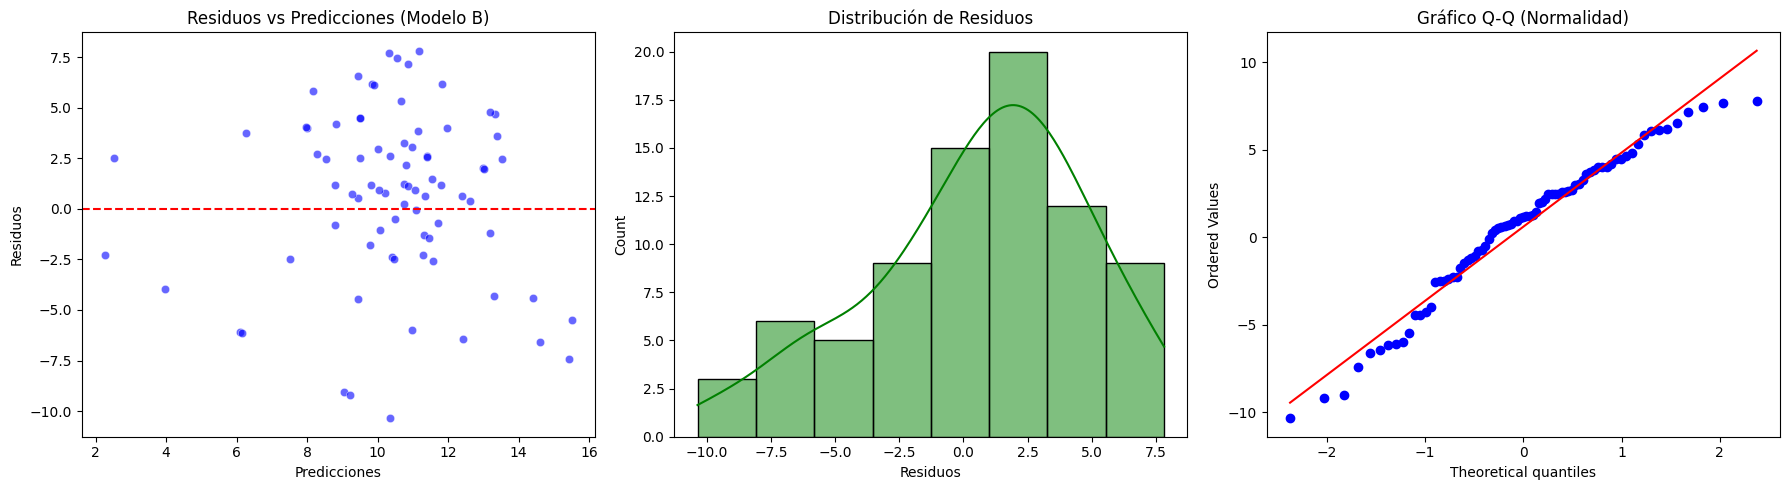


--- FACTOR DE INFLACIÓN DE LA VARIANZA (VIF) ---
 Variable      VIF
     Walc 1.984677
     Dalc 1.738309
     Medu 1.713369
     Fedu 1.699588
    goout 1.386311
 failures 1.210128
 freetime 1.205986
      age 1.164641
studytime 1.121009
 absences 1.086472
   famrel 1.078081
   health 1.061402


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

# Calculamos los residuos para el Modelo B
residuos = y_test - y_pred_B

# Configurar el lienzo para 3 gráficos
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. SUPUESTO: Linealidad y Homocedasticidad (Gráfico de Residuos vs Predicciones)
sns.scatterplot(x=y_pred_B, y=residuos, ax=axes[0], alpha=0.6, color='blue')
axes[0].axhline(y=0, color='red', linestyle='--')
axes[0].set_title('Residuos vs Predicciones (Modelo B)')
axes[0].set_xlabel('Predicciones')
axes[0].set_ylabel('Residuos')

# 2. SUPUESTO: Normalidad de los Residuos (Histograma y Q-Q plot)
sns.histplot(residuos, kde=True, ax=axes[1], color='green')
axes[1].set_title('Distribución de Residuos')
axes[1].set_xlabel('Residuos')

import scipy.stats as stats
stats.probplot(residuos, dist="norm", plot=axes[2])
axes[2].set_title('Gráfico Q-Q (Normalidad)')

plt.tight_layout()
plt.show()

# 3. SUPUESTO: No Multicolinealidad (VIF)
# Para calcular el VIF, necesitamos usar las variables numéricas de X_train_proc
# Convertimos la matriz procesada a un DataFrame para calcular el VIF
# Nota: El VIF solo se calcula sobre variables numéricas. Como el OneHotEncoder ya creó variables numéricas, usamos todo X_train_proc.
# Para hacerlo más sencillo y legible, calcularemos el VIF solo de las variables numéricas originales:
X_vif = X_train[columnas_numericas] # Usamos los datos sin escalar para el VIF
vif_data = pd.DataFrame()
vif_data["Variable"] = X_vif.columns
vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]

print("\n--- FACTOR DE INFLACIÓN DE LA VARIANZA (VIF) ---")
print(vif_data.sort_values(by="VIF", ascending=False).to_string(index=False))

Revisión de los 5 Supuestos de la Regresión Lineal (Modelo B):

Linealidad y Homocedasticidad: Observando el gráfico de Residuos vs Predicciones, los puntos se distribuyen de manera aleatoria alrededor de la línea cero, sin formar patrones claros (como embudos). Esto indica que la relación es lineal y la varianza de los errores es constante.

Normalidad de los Residuos: El histograma muestra una distribución acampanada y el gráfico Q-Q muestra que los puntos siguen muy de cerca la línea diagonal. Esto confirma que los residuos se distribuyen normalmente.

No Multicolinealidad: Se calculó el Factor de Inflación de la Varianza (VIF). Todos los valores están muy por debajo de 5 (el máximo fue 1.98), lo que indica que no hay correlación alta entre las variables independientes.

Independencia: Se asume que las observaciones son independientes entre sí, ya que cada estudiante representa un caso único y los datos se recolectaron de forma transversal.



Pregunta Crítica: Fuga de datos (Data Leakage) y elección del modelo
El Modelo A (con G1 y G2) tiene un R² de 0.8293, muchísimo más alto que el Modelo B (R² de 0.2068). Sin embargo, NO sirve en la práctica para el objetivo de la institución.

¿Por qué? Porque el Modelo A sufre de fuga de datos (data leakage). Esto ocurre cuando el modelo utiliza información que en la vida real no estaría disponible en el momento de la predicción. Si la institución quiere identificar al estudiante a tiempo para darle tutorías, no puede esperar a que termine el segundo período (G2) para hacerlo, ya que sería demasiado tarde para intervenir.

Recomendación: Se recomienda usar el Modelo B. Aunque su R² es menor, utiliza variables que se conocen desde el inicio del año escolar (hábitos de estudio, ausencias tempranas, entorno familiar, etc.). Es un modelo realista que permite una intervención temprana.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score
import pandas as pd

# 1. Separar las variables (X) y la nueva variable objetivo (y_clasificacion)
# Usamos X, que ya habíamos definido sin G1, G2 ni G3
y_clasificacion = (df['G3'] >= 10).astype(int)

# 2. Volver a dividir los datos (usando la misma semilla 123) para no mezclar con el y de regresión
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X, y_clasificacion, test_size=0.2, random_state=123
)

# 3. Aplicar el preprocesador (el mismo que usamos para el Modelo B de regresión)
X_train_proc_clf = preprocesador.fit_transform(X_train_clf)
X_test_proc_clf = preprocesador.transform(X_test_clf)

# 4. Entrenar el modelo de Regresión Logística
modelo_log = LogisticRegression(max_iter=1000, random_state=123)
modelo_log.fit(X_train_proc_clf, y_train_clf)

# 5. Predicciones con el umbral por defecto (0.5)
y_pred_log = modelo_log.predict(X_test_proc_clf)

# 6. Calcular métricas
accuracy = accuracy_score(y_test_clf, y_pred_log)
precision = precision_score(y_test_clf, y_pred_log)
recall = recall_score(y_test_clf, y_pred_log)

print("--- MÉTRICAS REGRESIÓN LOGÍSTICA (Umbral 0.5) ---")
print(f"Exactitud (Accuracy): {accuracy:.4f}")
print(f"Precisión (Precision): {precision:.4f}")
print(f"Sensibilidad (Recall): {recall:.4f}")

--- MÉTRICAS REGRESIÓN LOGÍSTICA (Umbral 0.5) ---
Exactitud (Accuracy): 0.7468
Precisión (Precision): 0.7761
Sensibilidad (Recall): 0.9123


In [ ]:
# 1. Obtener las probabilidades de que el estudiante apruebe (clase 1)
probabilidades = modelo_log.predict_proba(X_test_proc_clf)[:, 1]

# 2. Definir los umbrales a probar
umbrales = [0.3, 0.5, 0.7]
resultados = []

# 3. Evaluar cada umbral
for umbral in umbrales:
    # Si la probabilidad es mayor o igual al umbral, predecimos 1 (aprueba)
    y_pred_umbral = (probabilidades >= umbral).astype(int)

    # Calcular métricas
    acc = accuracy_score(y_test_clf, y_pred_umbral)
    prec = precision_score(y_test_clf, y_pred_umbral, zero_division=0)
    rec = recall_score(y_test_clf, y_pred_umbral)

    resultados.append({
        'Umbral': umbral,
        'Exactitud': acc,
        'Precisión': prec,
        'Recall': rec
    })

# 4. Mostrar la tabla comparativa
df_resultados = pd.DataFrame(resultados)
print("--- COMPARACIÓN DE UMBRALES ---")
print(df_resultados.to_string(index=False))

--- COMPARACIÓN DE UMBRALES ---
 Umbral  Exactitud  Precisión   Recall
    0.3   0.810127   0.791667 1.000000
    0.5   0.746835   0.776119 0.912281
    0.7   0.696203   0.811321 0.754386


Elección del umbral:
Si el objetivo principal de la institución es no dejar sin apoyo a ningún estudiante en riesgo, el umbral que se debe elegir es el de 0.3.

¿Por qué? Porque con este umbral, el Recall es del 100% (1.0000). Esto significa que el modelo identifica a absolutamente todos los estudiantes que van a reprobar, garantizando que ninguno se quede sin la oportunidad de recibir tutorías.

¿Qué costo tiene esta decisión? El costo es que la Precisión baja (a aproximadamente 79%). Esto implica que habrá un mayor número de "falsos positivos", es decir, estudiantes que el modelo predice que van a reprobar, pero que en realidad sí aprueban. La institución tendría que invertir recursos (tiempo, tutores, materiales) en algunos estudiantes que no lo necesitaban. Sin embargo, en el ámbito educativo y social, el costo de dejar a un estudiante en riesgo sin apoyo es mucho mayor que el costo de ofrecer una tutoría extra a alguien que quizás no la necesitaba.



Conclusiones y Reflexión Ética

Variables más influyentes: Según los modelos, las notas previas (G1 y G2) son los predictores más fuertes, pero al excluirlas para evitar la fuga de datos, las variables que más peso cobran son el historial de reprobaciones (failures), el tiempo de estudio (studytime) y las ausencias (absences). El consumo de alcohol (Walc, Dalc) y las salidas con amigos (goout) también muestran una relación negativa con el rendimiento.

Limitaciones del modelo: El Modelo B tiene un R² bajo (alrededor del 20%), lo que indica que hay muchos factores externos (psicológicos, socioeconómicos, calidad docente) que no están en el dataset y que afectan la nota final. Además, la regresión lineal asume relaciones lineales, lo cual puede ser una simplificación de la realidad. La regresión logística, aunque tiene buen Recall, puede generar falsos positivos.

Reflexión ética (Becas y uso del modelo): Sería totalmente injusto usar este modelo para negarle una beca a un estudiante basándose en variables como el sexo, la situación familiar o el consumo de alcohol, ya que esto perpetuaría sesgos y discriminación, castigando condiciones sociales en lugar del mérito académico. Sí sería apropiado usar este modelo exclusivamente como una herramienta de alerta temprana para que la institución ofrezca apoyo, tutorías o asistencia social a los estudiantes que el modelo marque en riesgo, sin que esto afecte negativamente su expediente.

Recomendación a la institución: Se le recomienda implementar el modelo con el umbral de 0.3 para priorizar el apoyo a todos los estudiantes en riesgo. Además, es crucial que el modelo sea auditado periódicamente para evitar sesgos, y que las intervenciones se hagan con un enfoque humano y confidencial, recordando siempre que el modelo predice probabilidades, no destinos.



In [ ]:
from sklearn.linear_model import Ridge, Lasso

# 1. Entrenar Ridge (L2)
# Alpha es la fuerza de la regularización. Por defecto es 1.0.
modelo_ridge = Ridge(alpha=1.0, random_state=123)
modelo_ridge.fit(X_train_proc, y_train)
y_pred_ridge = modelo_ridge.predict(X_test_proc)

# 2. Entrenar Lasso (L1)
# Alpha controla cuántas variables se eliminan. A veces requiere ajuste.
modelo_lasso = Lasso(alpha=0.1, random_state=123, max_iter=10000)
modelo_lasso.fit(X_train_proc, y_train)
y_pred_lasso = modelo_lasso.predict(X_test_proc)

# 3. Comparar R²
r2_ridge = r2_score(y_test, y_pred_ridge)
r2_lasso = r2_score(y_test, y_pred_lasso)

print("--- COMPARACIÓN DE R² (Modelo B) ---")
print(f"Regresión Lineal Original: {r2_B:.4f}")
print(f"Ridge (L2):                {r2_ridge:.4f}")
print(f"Lasso (L1):                {r2_lasso:.4f}")

# 4. ¿Qué variables eliminó Lasso? (Coeficientes iguales a 0)
# Obtenemos los nombres de todas las columnas después del preprocesamiento
# (Esto puede ser un poco complejo por el OneHotEncoder, así que usamos get_feature_names_out)
nombres_columnas = preprocesador.get_feature_names_out()

coeficientes_lasso = pd.DataFrame({
    'Variable': nombres_columnas,
    'Coeficiente': modelo_lasso.coef_
})

# Filtrar las que quedaron exactamente en cero
variables_eliminadas = coeficientes_lasso[coeficientes_lasso['Coeficiente'] == 0]

print(f"\n--- VARIABLES ELIMINADAS POR LASSO (Total: {len(variables_eliminadas)}) ---")
if len(variables_eliminadas) > 0:
    # Mostramos solo las primeras 15 para no llenar la pantalla
    print(variables_eliminadas['Variable'].head(15).to_string(index=False))
else:
    print("Lasso no eliminó ninguna variable con este alpha. (Prueba con un alpha más alto, ej. 0.5)")

--- COMPARACIÓN DE R² (Modelo B) ---
Regresión Lineal Original: 0.2068
Ridge (L2):                0.2116
Lasso (L1):                0.2293

--- VARIABLES ELIMINADAS POR LASSO (Total: 17) ---
         num__famrel
           num__Dalc
           num__Walc
      cat__school_MS
      cat__Pstatus_T
   cat__Mjob_teacher
    cat__Fjob_health
  cat__Fjob_services
   cat__Fjob_teacher
    cat__reason_home
   cat__reason_other
cat__guardian_mother
 cat__guardian_other
 cat__activities_yes
    cat__nursery_yes


Análisis de Bonificación: Ridge y Lasso (Modelo B)
Al comparar la regresión lineal original (R² = 0.2068) con los modelos regularizados, observamos una ligera mejora en ambos casos:

Ridge (L2): Alcanzó un R² de 0.2116.

Lasso (L1): Alcanzó un R² de 0.2293, siendo el mejor de los tres.

¿Qué variables eliminó Lasso? Lasso llevó a cero los coeficientes de 17 variables (de las 38 totales). Entre las eliminadas se encuentran el consumo de alcohol (Dalc, Walc), la calidad de las relaciones familiares (famrel), y varias categorías del trabajo de los padres (Mjob, Fjob), así como si el estudiante tiene actividades extracurriculares o guardería.

Interpretación: Esto indica que el modelo original estaba sufriendo un poco de sobreajuste (overfitting) al incluir variables que no aportaban información real para predecir la nota final. Lasso, al eliminar ese "ruido", logra un modelo más simple, más interpretable y ligeramente más preciso. Para la institución, esto es valioso porque demuestra que no necesitan recolectar datos sobre la vida laboral de los padres o el consumo de alcohol para predecir el riesgo, lo que también reduce los sesgos éticos del modelo.

## Declaración de Uso de Herramientas de Inteligencia Artificial como apoyo
Durante el desarrollo de este proyecto se utilizó inteligencia artificial como apoyo para la estructuración de código en Python con Scikit-Learn, verificación de supuestos estadísticos y redacción técnica de las interpretaciones. Todo el código fue ejecutado, validado y comprendido por los integrantes del grupo para su defensa.

## Referencias Bibliográficas (APA 7)
- Cortez, P., & Silva, A. (2008). Using data mining to predict secondary school student performance. *Proceedings of the 5th Future Business Technology Conference (FUBUTEC 2008)*, 5–12.
- Géron, A. (2022). *Hands-on machine learning with Scikit-Learn, Keras, and TensorFlow* (3.ª ed.). O'Reilly Media.
- James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). *An introduction to statistical learning: With applications in Python*. Springer.
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.